In [1]:
import pandas as pd

raw = pd.read_csv("datasets/A4/Tabla_InformalidadLaboral_banxico.csv", encoding="latin-1",
                  skiprows=3, header=None, names=["year","quarter","Norte","Centro Norte","Centro","Sur"])
print(raw.head())
raw = raw[raw["quarter"].astype(str).str.contains(r"-\d\d")].copy()   # keep data rows only
display(raw.head())
raw["year"] = raw["year"].replace("", pd.NA).ffill().astype(int)
display(raw.head())
for c in ["Norte","Centro Norte","Centro","Sur"]:
    raw[c] = pd.to_numeric(raw[c])

informal = (raw[raw["year"] <= 2025]
            .groupby("year")[["Norte","Centro Norte","Centro","Sur"]].mean().round(1))
display(informal)

   year quarter  Norte  Centro Norte  Centro    Sur
0  2019  ene-19  38.94         54.50   59.25  70.80
1   NaN  abr-19  38.82         53.64   58.47  69.89
2   NaN  jul-19  38.62         54.00   58.48  69.51
3   NaN  oct-19  38.51         54.07   58.35  69.17
4  2020  ene-20  39.08         53.74   58.21  69.09


,year,quarter,Norte,Centro Norte,Centro,Sur
0,2019,ene-19,38.94,54.50,59.25,70.80
1,NaN,abr-19,38.82,53.64,58.47,69.89
2,NaN,jul-19,38.62,54.00,58.48,69.51
3,NaN,oct-19,38.51,54.07,58.35,69.17
4,2020,ene-20,39.08,53.74,58.21,69.09


,year,quarter,Norte,Centro Norte,Centro,Sur
0,2019,ene-19,38.94,54.50,59.25,70.80
1,2019,abr-19,38.82,53.64,58.47,69.89
2,2019,jul-19,38.62,54.00,58.48,69.51
3,2019,oct-19,38.51,54.07,58.35,69.17
4,2020,ene-20,39.08,53.74,58.21,69.09


,Norte,Centro Norte,Centro,Sur
year,,,,
2019,38.7,54.1,58.6,69.8
2020,37.5,51.8,56.2,67.4
2021,38.6,52.5,58.0,70.5
2022,38.3,52.4,57.5,69.7
2023,38.0,52.3,56.8,69.3
2024,37.3,52.2,55.7,69.1
2025,37.7,52.8,56.4,69.4


In [2]:
import pandas as pd, glob, os, re, unicodedata

def norm(s):
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z]", "", s)

crime = pd.read_csv("datasets/A4/Estatal-Delitos-2015-2025_sep2026.csv", encoding="latin-1")
states = crime[["Clave_Ent", "Entidad"]].drop_duplicates()

display(crime.head())

meses = [
    "Enero",
    "Febrero",
    "Marzo",
    "Abril",
    "Mayo",
    "Junio",
    "Julio",
    "Agosto",
    "Septiembre",
    "Octubre",
    "Noviembre",
    "Diciembre",
]

#Sum the 12 months to get the annual crime total per row
crime["Total_Anual"] = crime[meses].sum(axis=1)

#Group by Entidad and Tipo de delito (using .sum() for total crimes, or .mean() for yearly average)
crimes = (
    crime.groupby(["Entidad", "Tipo de delito"], as_index=False)["Total_Anual"]
    .sum()
    .sort_values(["Entidad", "Total_Anual"], ascending=[True, False])
)
display(crimes.head(6))
print()


#Pivot so each unique Entidad is ONE row, and each Tipo de delito is a column
tabla_estados = crime.pivot_table(
    index=["Clave_Ent", "Entidad"],  # Unique rows (32 states)
    columns="Tipo de delito",  # Each crime type becomes its own column
    values="Total_Anual",  # Values to aggregate
    aggfunc="sum",  # Total crimes (2015-2025)
    fill_value=0,  # Replace any missing values with 0
).reset_index()

#Clean up the column axis name left by pivot_table
tabla_estados.columns.name = None

print(tabla_estados.shape)  # Should be (32, ~42)
display(tabla_estados.head(32))


,Año,Clave_Ent,Entidad,Bien jurídico afectado,Tipo de delito,Subtipo de delito,Modalidad,Enero,Febrero,Marzo,Abril,Mayo,Junio,Julio,Agosto,Septiembre,Octubre,Noviembre,Diciembre
0,2015,1,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio doloso,Con arma de fuego,3,0,2,1,1,1,2,1,2,2,2,1
1,2015,1,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio doloso,Con arma blanca,1,1,0,0,0,1,0,1,0,0,0,1
2,2015,1,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio doloso,Con otro elemento,0,0,2,2,3,2,0,1,2,0,0,0
3,2015,1,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio doloso,No especificado,2,0,0,1,0,0,0,0,0,0,0,0
4,2015,1,Aguascalientes,La vida y la Integridad corporal,Homicidio,Homicidio culposo,Con arma de fuego,0,0,0,0,1,0,0,0,0,0,0,0


,Entidad,Tipo de delito,Total_Anual
32,Aguascalientes,Robo,127917
22,Aguascalientes,Lesiones,48039
8,Aguascalientes,Daño a la propiedad,42574
5,Aguascalientes,Amenazas,31831
27,Aguascalientes,Otros delitos del Fuero Común,29855
39,Aguascalientes,Violencia familiar,22256



(32, 42)


,Clave_Ent,Entidad,Aborto,Abuso de confianza,Abuso sexual,Acoso sexual,Allanamiento de morada,Amenazas,Contra el medio ambiente,Corrupción de menores,...,Otros delitos que atentan contra la vida y la integridad corporal,Rapto,Robo,Secuestro,Trata de personas,Tráfico de menores,Violación equiparada,Violación simple,Violencia de género en todas sus modalidades distinta a la violencia familiar,Violencia familiar
0,1,Aguascalientes,91,7575,19,0,5194,31831,523,715,...,494,0,127917,59,25,7,1037,2199,102,22256
1,2,Baja California,548,6807,15799,574,28363,49094,243,4944,...,18454,1,402897,139,384,22,3495,7098,0,127549
2,3,Baja California Sur,101,3340,3445,1010,2106,16665,34,542,...,1741,1,83021,26,28,0,332,2122,63,27679
3,4,Campeche,14,1062,1396,225,1660,8325,60,161,...,986,0,23048,38,20,0,1737,794,0,6406
4,5,Coahuila de Zaragoza,31,6422,7478,3321,7419,65028,123,433,...,409,15,88494,98,92,1,2329,1689,853,112281
5,6,Colima,27,4207,2869,295,1871,24608,36,307,...,1,0,70609,83,11,0,34,1478,0,34673
6,7,Chiapas,112,1668,2164,704,1241,9871,541,531,...,1231,32,57004,177,286,18,386,5134,1,30701
7,8,Chihuahua,99,10703,16757,1404,6415,34750,521,1346,...,4271,0,162360,302,366,12,2881,10362,174,138235
8,9,Ciudad de México,1555,43917,36174,10572,8774,163607,9774,2834,...,6888,63,936038,822,1040,25,8707,9278,0,305775
9,10,Durango,17,6440,4691,649,1566,15419,11,110,...,390,1,83697,41,7,1,65,2660,25,56669


In [3]:
import pandas as pd, glob, os, re, unicodedata

def norm(s):
    s = unicodedata.normalize("NFKD", s).encode("ascii", "ignore").decode().lower()
    return re.sub(r"[^a-z]", "", s)

crime = pd.read_csv("datasets/A4/Estatal-Delitos-2015-2025_sep2026.csv", encoding="latin-1")
states = crime[["Clave_Ent", "Entidad"]].drop_duplicates()

def match_state(name):
    key = norm(name)
    alias = {"edomex": "Mexico", "estadodemexico": "Mexico", "mexico": "Mexico",
             "cdmx": "Ciudad de Mexico", "distritofederal": "Ciudad de Mexico",
             "coahuila": "Coahuila de Zaragoza",
             "michoacan": "Michoacan de Ocampo",
             "veracruz": "Veracruz de Ignacio de la Llave"}
    if key in alias:
        return states[states.Entidad.map(norm) == norm(alias[key])]
    exact = states[states.Entidad.map(norm) == key]      # exact match first
    if len(exact) == 1:
        return exact
    return states[states.Entidad.map(lambda e: norm(e).startswith(key))]

def read_inegi(path):
    txt = open(path, "rb").read().decode("utf-16")
    rows = [l.replace('"', '').split(",") for l in txt.splitlines()
            if re.match(r'"\d{4}/\d\d"', l)]
    df = pd.DataFrame(rows, columns=["periodo", "valor"])
    df["valor"] = pd.to_numeric(df["valor"], errors="coerce")   # 'ND' -> NaN
    df["Año"] = df["periodo"].str[:4].astype(int)
    return df

frames = []
for f in glob.glob("datasets/A4/Informalidad/Informalidad*.csv"):
    nombre = os.path.basename(f).replace("Informalidad", "").replace(".csv", "").strip("_ -")
    hit = match_state(nombre)
    assert len(hit) == 1, f"Could not match state for file: {f} -> {nombre}"
    d = read_inegi(f)
    d["Clave_Ent"] = hit.Clave_Ent.iloc[0]
    frames.append(d)

inf = pd.concat(frames)
informalidad = (inf[inf["Año"].between(2015, 2025)]
                .groupby(["Clave_Ent", "Año"], as_index=False)
                .agg(informalidad=("valor", "mean"), n_trim=("valor", "count")))

print(informalidad["Clave_Ent"].nunique(), "states (expect 32)")
print(informalidad.shape, "(expect 352 rows)")
print(informalidad[informalidad["Año"] == 2025].sort_values("informalidad").iloc[[0, 1, -2, -1]])

32 states (expect 32)
(352, 4) (expect 352 rows)
     Clave_Ent   Año  informalidad  n_trim
54           5  2025     33.486808       4
208         19  2025     33.950756       4
76           7  2025     76.471155       4
219         20  2025     78.729617       4


In [4]:
#Checks
import difflib

official = {norm(e): e for e in states.Entidad}

frames, problems = [], []
for f in sorted(glob.glob("datasets/A4/Informalidad/Informalidad*.csv")):
    nombre = os.path.basename(f).replace("Informalidad", "").replace(".csv", "").strip("_ -")
    hit = match_state(nombre)
    if len(hit) != 1:
        sug = difflib.get_close_matches(norm(nombre), official.keys(), n=1, cutoff=0.8)
        problems.append((os.path.basename(f), official[sug[0]] if sug else "no suggestion"))
        continue
    d = read_inegi(f)
    d["Clave_Ent"] = hit.Clave_Ent.iloc[0]
    frames.append(d)

if problems:
    for fname, suggestion in problems:
        print(f"UNMATCHED: {fname}  ->  closest official name: {suggestion}")
    raise SystemExit(f"{len(problems)} file(s) need renaming. Fix them and rerun.")

inf = pd.concat(frames)
informalidad = (inf[inf["Año"].between(2015, 2025)]
                .groupby(["Clave_Ent", "Año"], as_index=False)
                .agg(informalidad=("valor", "mean"), n_trim=("valor", "count")))
#SanityChecks
print(informalidad["Clave_Ent"].nunique(), "states (expect 32)")
print(informalidad.shape, "(expect (352, 4))")
print(informalidad[informalidad["Año"] == 2025].sort_values("informalidad").iloc[[0, 1, -2, -1]])
print("n_trim < 4 only in:", informalidad[informalidad["n_trim"] < 4]["Año"].unique())

32 states (expect 32)
(352, 4) (expect (352, 4))
     Clave_Ent   Año  informalidad  n_trim
54           5  2025     33.486808       4
208         19  2025     33.950756       4
76           7  2025     76.471155       4
219         20  2025     78.729617       4
n_trim < 4 only in: [2020]


(352, 3) (expect (352, 3))
132.833801 million in 2025 (expect roughly 130-135)

(352, 8) | missing values: [0, 0, 0]
region
Centro           8
Centro Norte    10
Norte            6
Sur              8
Name: Entidad, dtype: int64
      spearman  pearson
Año                    
2015     -0.44    -0.44
2016     -0.48    -0.44
2017     -0.41    -0.43
2018     -0.36    -0.40
2019     -0.39    -0.39
2020     -0.34    -0.38
2021     -0.34    -0.39
2022     -0.34    -0.39
2023     -0.33    -0.37
2024     -0.33    -0.38
2025     -0.40    -0.35


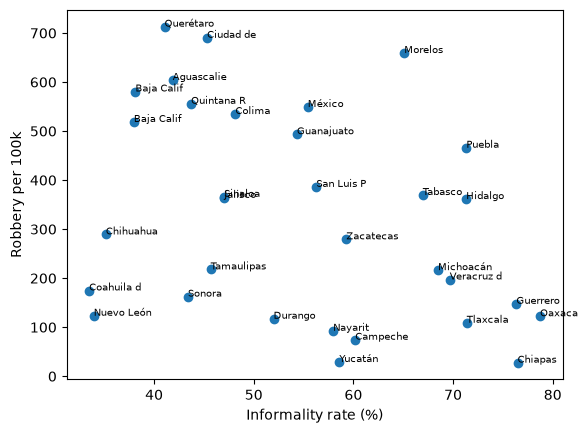

In [5]:
#small dataset
pop = pd.read_csv("datasets/A4/poblacion_2015_2025.csv")
pop_state = (pop[(pop["CVE_GEO"] != 0) & pop["AÑO"].between(2015, 2025)]
             .groupby(["AÑO", "CVE_GEO"], as_index=False)["POBLACION"].sum())

print(pop_state.shape, "(expect (352, 3))")
print(pop_state[pop_state["AÑO"] == 2025]["POBLACION"].sum() / 1e6, "million in 2025 (expect roughly 130-135)")
print()
# 2) Robbery per state-year
months = ["Enero","Febrero","Marzo","Abril","Mayo","Junio","Julio",
          "Agosto","Septiembre","Octubre","Noviembre","Diciembre"]
crime["total"] = crime[months].sum(axis=1)
robo = (crime[crime["Tipo de delito"] == "Robo"]
        .groupby(["Año", "Clave_Ent", "Entidad"], as_index=False)["total"].sum())

#Merge crime + population, then + informality
df = robo.merge(pop_state, left_on=["Año", "Clave_Ent"],
                right_on=["AÑO", "CVE_GEO"], how="left").drop(columns=["AÑO", "CVE_GEO"])
df["robo_por_100k"] = df["total"] / df["POBLACION"] * 100_000
df = df.merge(informalidad[["Clave_Ent", "Año", "informalidad"]],
              on=["Clave_Ent", "Año"], how="left")

#Banxico regions (verify against Banxico's own definition)
norte  = ["Baja California","Chihuahua","Coahuila de Zaragoza","Nuevo León","Sonora","Tamaulipas"]
cnorte = ["Aguascalientes","Baja California Sur","Colima","Durango","Jalisco",
          "Michoacán de Ocampo","Nayarit","San Luis Potosí","Sinaloa","Zacatecas"]
sur    = ["Campeche","Chiapas","Guerrero","Oaxaca","Quintana Roo","Tabasco",
          "Veracruz de Ignacio de la Llave","Yucatán"]
df["region"] = df["Entidad"].map(lambda e: "Norte" if e in norte else
                                 "Centro Norte" if e in cnorte else
                                 "Sur" if e in sur else "Centro")

# 5) Integrity checks
print(df.shape, "| missing values:", df[["POBLACION", "robo_por_100k", "informalidad"]].isna().sum().tolist())
print(df.groupby("region")["Entidad"].nunique())

#Correlation by year (Spearman = robust with only 32 points and outliers)
corr = (df.groupby("Año")
          .apply(lambda g: pd.Series({"spearman": g["robo_por_100k"].corr(g["informalidad"], method="spearman"),
                                      "pearson":  g["robo_por_100k"].corr(g["informalidad"])}))
          .round(2))
print(corr)

#Quick scatter for 2025 for eyeball
import matplotlib.pyplot as plt
g = df[df["Año"] == 2025]
plt.scatter(g["informalidad"], g["robo_por_100k"])
for _, r in g.iterrows():
    plt.annotate(r["Entidad"][:10], (r["informalidad"], r["robo_por_100k"]), fontsize=7)
plt.xlabel("Informality rate (%)"); plt.ylabel("Robbery per 100k"); plt.show()

Correlation:

Spearman runs from -0.33 to -0.48 and Pearson from -0.35 to -0.44 across all 11 years. 

1. A moderate negative association: states with more informal employment tend to record less robbery per capita.
2. It isn't driven by one outlier. Spearman is the one that resists outliers.
3. With 32 states, a correlation of about ±0.35 is roughly the borderline for statistical significance. 
The 11 years aren't 11 independent confirmations either, because they're the same 32 states. >  consistent moderate negative relationship, not a strong or proven one.

Scatter:
Low informality, high recorded robbery: Querétaro, Ciudad de México, Aguascalientes, Baja California.
High informality, low recorded robbery: Chiapas, Oaxaca, Guerrero, Yucatán.
Exceptions to the trend: Morelos and Puebla (high on both), and Chihuahua, Coahuila and Nuevo León (low on both).

This doesn't mean informality protects against robbery. Reporting, urbanization and opportunity probably explain a lot of it.

In [6]:
print(df.shape[0] == 352, f"Expected 352 state-year rows, got {df.shape[0]}")


True Expected 352 state-year rows, got 352


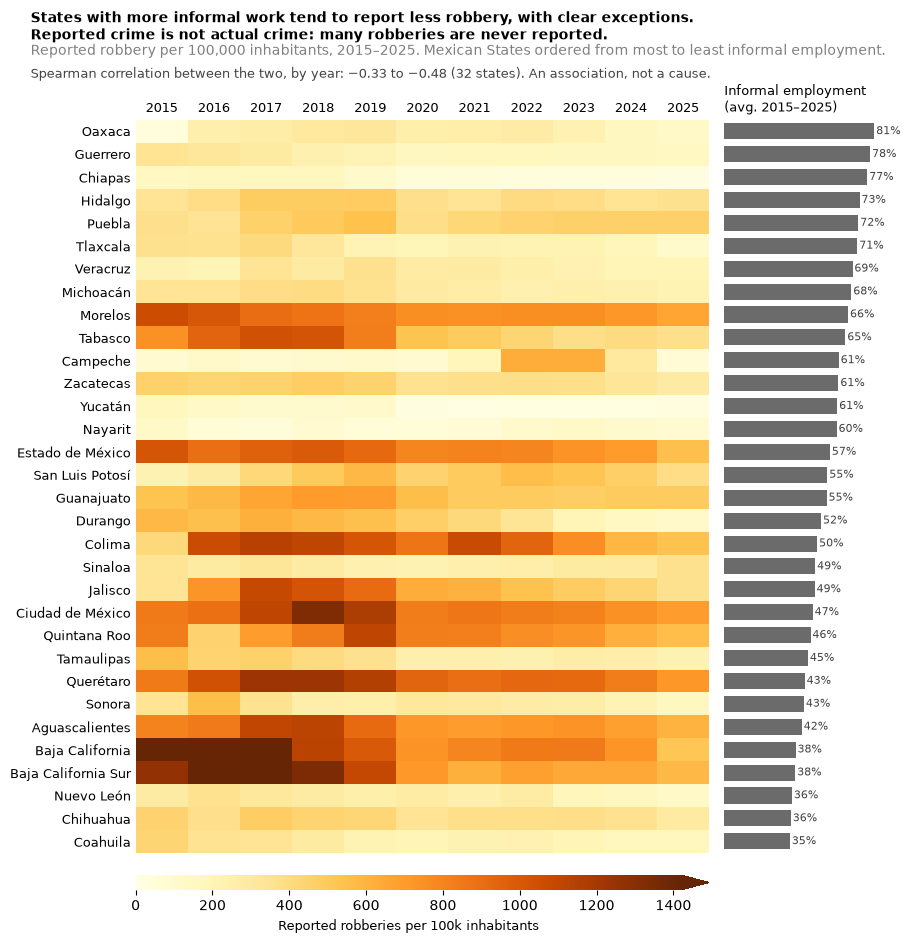

In [7]:
import numpy as np
import matplotlib.pyplot as plt

#shot names
short = {"Coahuila de Zaragoza": "Coahuila", "Michoacán de Ocampo": "Michoacán",
         "Veracruz de Ignacio de la Llave": "Veracruz", "México": "Estado de México"}
d = df.copy()
d["estado"] = d["Entidad"].replace(short)

#Order states by average informality 2015-2025 (highest at top)
orden = d.groupby("estado")["informalidad"].mean().sort_values(ascending=False)
heat = d.pivot(index="estado", columns="Año", values="robo_por_100k").loc[orden.index]

fig = plt.figure(figsize=(10, 10))
gs = fig.add_gridspec(2, 2, width_ratios=[4, 1.3], height_ratios=[30, 0.6],
                      wspace=0.04, hspace=0.06) ######################################0.12 > 0.06
ax = fig.add_subplot(gs[0, 0]); axb = fig.add_subplot(gs[0, 1], sharey=ax)
cax = fig.add_subplot(gs[1, 0])

im = ax.imshow(heat.values, aspect="auto", cmap="YlOrBr",
               vmin=0, vmax=np.nanpercentile(heat.values, 99))
ax.set_xticks(range(heat.shape[1])); ax.set_xticklabels(heat.columns, fontsize=9)
ax.set_yticks(range(heat.shape[0])); ax.set_yticklabels(heat.index, fontsize=9)
ax.xaxis.tick_top(); ax.tick_params(length=0)
for s in ax.spines.values(): s.set_visible(False)

axb.barh(range(len(orden)), orden.values, color="#6b6b6b", height=0.7)
for i, v in enumerate(orden.values):
    axb.text(v + 1, i, f"{v:.0f}%", va="center", fontsize=8, color="#444")
axb.set_xlim(0, 100); axb.set_xticks([]); axb.tick_params(left=False, labelleft=False)
for s in axb.spines.values(): s.set_visible(False)
axb.set_title("Informal employment\n(avg. 2015–2025)", fontsize=9, loc="left")

cb = fig.colorbar(im, cax=cax, orientation="horizontal", extend="max")
cb.set_label("Reported robberies per 100k inhabitants", fontsize=9)
cb.outline.set_visible(False)

fig.suptitle("States with more informal work tend to report less robbery, with clear exceptions. "
         "\nReported crime is not actual crime: many robberies are never reported.", 
             x=0.02, ha="left", fontsize=10, fontweight="bold", y=0.99, )
fig.text(0.02, 0.945, "Reported robbery per 100,000 inhabitants, 2015–2025. "
         "Mexican States ordered from most to least informal employment.", fontsize=10, color="gray")
fig.text(0.02, 0.922, "Spearman correlation between the two, by year: −0.33 to −0.48 "
         "(32 states). An association, not a cause.", fontsize=9, color="#444")

#####
plt.show()

States are rows, ordered from most to least informal, and years are columns. Color is robbery per 100,000, and a bar column on the right shows informality.

*One color scale shared across all years so colors are comparable, color starting at zero, no numbers inside the cells (high data-ink ratio), a single-hue palette, and the caveat sitting directly in the figure.
*A natural optional extension is ENVIPE, INEGI's victimization survey, which estimates unreported crime by state.

Heatmap shows
The gradient is visible. The eight most informal states (Oaxaca, Guerrero, Chiapas, Hidalgo, Puebla, Tlaxcala, Veracruz, Michoacán) all sit in pale-to-moderate colors. The darkest rows are at the bottom: Baja California, Baja California Sur, Aguascalientes, Querétaro.
The exceptions are visible too. Morelos, Tabasco and Estado de México are dark despite high informality. Coahuila, Chihuahua and Nuevo León are pale despite low informality. That matches your scatterplot, and it keeps you from overselling the correlation.
A second pattern appeared that we hadn't planned for: reported robbery fell almost everywhere over time

Sources:
"Fuente: INEGI, [enoe]".
"Fuente BANXICO"
"Fuente SESNP & CONAPO"
https://www.inegi.org.mx/programas/enoe/15ymas/
https://www.banxico.org.mx/TablasWeb/reportes-economias-regionales/abril-junio-2026/A327E7E4-96C9-415E-B0DF-032FF37147A0.html
https://www.gob.mx/sesnsp/acciones-y-programas/datos-abiertos-de-incidencia-delictiva
https://www.gob.mx/conapo/documentos/bases-de-datos-de-la-conciliacion-demografica-1950-a-2019-y-proyecciones-de-la-poblacion-de-mexico-2020-a-2070


INEGI (ENOE informality): 
INEGI's "Términos de Libre Uso" let you copy, distribute, publish and adapt its information. They require that you credit INEGI, using the format. 
SESNSP and CONAPO: both are published as Mexican government open data.